# Neuroninis tinklas: šeši Fakeddit įrašų tipai pagal antraštę

Ta pati užduotis kaip šešių klasių antraščių užrašų knygelėje (`04_text_classification.ipynb`): kiekviena Reddit įrašo antraštė priskiriama vienai iš šešių Fakeddit klasių (**tikras**, **satyra / parodija**, **klaidingas ryšys**, **apsimetėlio turinys**, **redaguotas turinys**, **klaidinantis turinys**), naudojant tik antraštės tekstą ir oficialų padalijimą. Sukuriami du Keras tinklai ir palyginami su tiesiniu SVM iš tos užrašų knygelės:

1. **BiGRU**: nedidelis rekurentinis tinklas, mokomas nuo nulio.
2. **DistilBERT**: transformeris, iš anksto išmokytas su angliškais tekstais ir papildomai pritaikytas antraštėms.

Keras veikia su PyTorch backend. TensorFlow natūraliame Windows negali naudoti GPU, o PyTorch gali, todėl mokoma su GPU.

In [1]:
import os, warnings
os.environ["KERAS_BACKEND"] = "torch"  # turi buti nustatyta pries importuojant keras
import numpy as np, pandas as pd, matplotlib.pyplot as plt, joblib, keras, keras_hub
from collections import Counter
from pathlib import Path
from keras import layers
from huggingface_hub import snapshot_download
from tokenizers import BertWordPieceTokenizer
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

DATA = Path("../data/multimodal_only_samples-20261006T085257Z-1-001/multimodal_only_samples")
FIG = Path("../report/figures"); FIG.mkdir(parents=True, exist_ok=True)
MODELS = Path("../models")
CLASSES = ["true", "satire/parody", "false connection", "imposter content", "manipulated content", "misleading content"]  # 6_way_label 0-5
warnings.filterwarnings("ignore", message="RNN module weights|Skipping variable loading for optimizer")  # ispejimai apie GRU atminti ir neikelta optimizatoriu, rezultatams netrukdo

## 1. Duomenų įkėlimas
Oficialus Fakeddit padalijimas. Žymės paverčiamos one-hot eilutėmis (1 klasės stulpelyje), kurių reikia nuostolių funkcijai ir macro F1 metrikai.

In [2]:
COLS = ["clean_title", "6_way_label"]
load = lambda name: pd.read_csv(DATA / f"multimodal_{name}.tsv", sep="\t", usecols=COLS)
train, val, test = load("train"), load("validate"), load("test_public")
y, y_val, y_test = (df["6_way_label"].values for df in (train, val, test))
Y, Y_val = keras.utils.to_categorical(y, 6), keras.utils.to_categorical(y_val, 6)
half = dict(enumerate((len(y) / (6 * np.bincount(y))) ** 0.5))  # tie patys puse stiprumo svoriai kaip SVM: retos klases svarbesnes, bet ne 19 kartu
train.shape, val.shape, test.shape

((564000, 2), (59342, 2), (59319, 2))

In [3]:
words = train["clean_title"].str.split().str.len()
words.quantile([0.5, 0.95, 0.99]).rename("words per title")

0.50     6.0
0.95    17.0
0.99    27.0
Name: words per title, dtype: float64

Pusė antraščių turi 6 ar mažiau žodžių, o 99 % - ne daugiau kaip 27, todėl 32 pozicijos antraštei BiGRU tinkle (40 DistilBERT, kurio žodžių dalys trumpesnės už žodžius) beveik nieko nepraranda.

## 2. BiGRU, mokomas nuo nulio

### Antraščių pavertimas skaičiais
Kiekvienas žodis, mokymo antraštėse pasitaikęs bent du kartus, gauna savo numerį (apie 55 000 žodžių). Numeris 0 užpildo tuščias pozicijas, o numeris 1 reiškia nežinomą žodį. Kiekviena antraštė tampa 32 skaičių eilute, nukirpta arba papildyta.

In [4]:
counts = Counter(w for t in train["clean_title"] for w in t.split())
vocab = {w: i + 2 for i, (w, k) in enumerate(counts.most_common()) if k >= 2}  # 0 tuscia vieta, 1 nezinomas zodis; vienkartiniai zodziai nieko neismoktu

def word_ids(titles, length=32):
    ids = np.zeros((len(titles), length), dtype="int32")
    for row, title in enumerate(titles):
        nums = [vocab.get(w, 1) for w in title.split()[:length]]
        ids[row, :len(nums)] = nums
    return ids

W, W_val, W_test = (word_ids(df["clean_title"]) for df in (train, val, test))
print("Vocabulary:", len(vocab) + 2, " example:", train["clean_title"][0], W[0][:12])

Vocabulary: 54803  example: my walgreens offbrand mucinex was engraved with the letters mucinex but in a different order [    8  9437 19932 31054    25  9282    14     2  2266 31054    70     5]


### Architektūra

| Sluoksnis | Išvestis vienai antraštei | Paskirtis | Aktyvacija |
|---|---|---|---|
| Įvestis | 32 žodžių numeriai | antraštė kaip žodžių numeriai | |
| Embedding | 32 × 128 | kiekvienam žodžiui išmoksta 128 skaičių vektorių; panašiose antraštėse naudojami žodžiai gauna panašius vektorius | nėra (paieškos lentelė) |
| Dvikryptis GRU | 32 × 128 | skaito antraštę iš kairės į dešinę ir iš dešinės į kairę (po 64 neuronus kiekviena kryptimi), todėl kiekviena pozicija turi visos antraštės kontekstą; to TF-IDF negali | tanh naujai būsenai, sigmoid vartams, kurie sprendžia, ką palikti ir ką pamiršti |
| Global max pooling | 128 | palieka stipriausią kiekvieno požymio reikšmę bet kurioje antraštės vietoje, todėl antraštės ilgis nesvarbus | |
| Dense | 64 | sujungia požymius į klasių įrodymus | ReLU |
| Dropout 0,3 | 64 | mokymo metu atsitiktinai išjungia 30 % reikšmių, kad tinklas nepasikliautų keliais požymiais | |
| Dense (išvestis) | 6 | po vieną tikimybę kiekvienai klasei, jų suma 1 | softmax |

### Mokymo parametrai
* **Nuostolių funkcija**: kategorinė kryžminė entropija, įprasta, kai renkamasi viena klasė iš kelių.
* **Optimizatorius**: Adam su mokymosi greičiu 0,001; jis kiekvienam svoriui atskirai pritaiko žingsnio dydį.
* **Paketo dydis** 256 antraštės, iki 10 perėjimų per mokymo duomenis (epochų).
* **Klasių svoriai**: tie patys perpus sumažinti svoriai kaip SVM, kad klaidos su retomis klasėmis kainuotų daugiau.
* **Ankstyvas sustabdymas**: po kiekvienos epochos tikrinamas macro F1 validacijos duomenyse; mokymas sustoja, kai jis 2 epochas negerėja, ir paliekami geriausios epochos svoriai.

Mokymas užtrunka kelias minutes; tinklas ir jo istorija išsaugomi `models/` ir vėliau tik įkeliami (norint mokyti iš naujo, failus reikia ištrinti).

In [5]:
GRU_PATH, GRU_HIST = MODELS / "bigru_6way.keras", MODELS / "bigru_6way_history.csv"
if GRU_PATH.exists():
    gru = keras.saving.load_model(GRU_PATH, compile=False)  # tik spejimams, optimizatoriaus nereikia
    gru_hist = pd.read_csv(GRU_HIST, index_col="epoch")
else:
    keras.utils.set_random_seed(42)  # kad perleidus gautusi tie patys svoriai
    gru = keras.Sequential([
        keras.Input((32,), dtype="int32"),
        layers.Embedding(len(vocab) + 2, 128),
        layers.Bidirectional(layers.GRU(64, return_sequences=True)),  # grazina visas pozicijas, kad pooling galetu rinktis
        layers.GlobalMaxPooling1D(),
        layers.Dense(64, activation="relu"),
        layers.Dropout(0.3),
        layers.Dense(6, activation="softmax"),
    ])
    gru.compile(keras.optimizers.Adam(1e-3), "categorical_crossentropy",
                metrics=[keras.metrics.F1Score(average="macro", name="macro_f1"), "accuracy"])
    h = gru.fit(W, Y, validation_data=(W_val, Y_val), batch_size=256, epochs=10, class_weight=half, verbose=2,
                callbacks=[keras.callbacks.EarlyStopping("val_macro_f1", mode="max", patience=2, restore_best_weights=True)])  # stabdom kai validacijos F1 nebekyla
    gru.save(GRU_PATH)
    gru_hist = pd.DataFrame(h.history).rename_axis("epoch"); gru_hist.to_csv(GRU_HIST)
gru.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 32, 128)        │     7,014,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 32, 128)        │        74,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling1d            │ (None, 128)            │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,097,926 (27.08 MB)

 Trainable params: 7,097,926 (27.08 MB)

 Non-trainable params: 0 (0.00 B)

## 3. Pritaikytas DistilBERT

### Kodėl iš anksto išmokytas tinklas
BiGRU pradeda nuo atsitiktinių žodžių vektorių ir mokosi tik iš šių antraščių. Iš anksto išmokytas transformeris jau moka anglų kalbą, nes perskaitė daug teksto (DistilBERT mokytas su tomis pačiomis knygomis ir Vikipedijos tekstais kaip BERT), todėl pritaikant jį reikia išmokyti tik šešių klasių. DistilBERT yra mažesnė BERT kopija: 6 sluoksniai vietoj 12, apie 40 % mažiau svorių, išlaikant didžiąją dalį BERT tikslumo, todėl jį galima mokyti nešiojamojo kompiuterio GPU.

### Antraščių pavertimas skaičiais
DistilBERT turi savo žodyną iš 30 522 **žodžių dalių**. Dažni žodžiai lieka sveiki, o reti suskaidomi į žinomas dalis (`walgreens` tampa `wal ##gree ##ns`), todėl nežinomų žodžių nėra. Pradžioje pridedama `[CLS]` dalis, pabaigoje `[SEP]`. Užpildymo kaukė nurodo tinklui, kurios pozicijos yra tikros dalys, o kurios - užpildas.

In [6]:
BERT = snapshot_download("keras/distil_bert_base_en_uncased")  # ~250 MB, atsisiuncia tik pirma karta
tok = BertWordPieceTokenizer(os.path.join(BERT, "assets", "tokenizer", "vocabulary.txt"), lowercase=True)  # greitas tokenizatorius; KerasHub savasis Windows'e be tensorflow-text labai letas
tok.enable_truncation(40); tok.enable_padding(length=40)

def pieces(titles):
    ids = np.array([e.ids for e in tok.encode_batch(titles.tolist())], dtype="int32")
    return {"token_ids": ids, "padding_mask": ids != 0}

P, P_val, P_test = (pieces(df["clean_title"]) for df in (train, val, test))
print(tok.encode(train["clean_title"][0]).tokens)

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 7 files:   0%|          | 0/7 [00:00<?, ?it/s]

['[CLS]', 'my', 'wal', '##gree', '##ns', 'off', '##brand', 'mu', '##cine', '##x', 'was', 'engraved', 'with', 'the', 'letters', 'mu', '##cine', '##x', 'but', 'in', 'a', 'different', 'order', '[SEP]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]']


### Architektūra

| Dalis | Išvestis vienai antraštei | Paskirtis | Aktyvacija |
|---|---|---|---|
| Įvestys | 40 dalių numerių + 40 reikšmių užpildymo kaukė | antraštė kaip žodžių dalys | |
| Dalių ir pozicijų embedding | 40 × 768 | vektorius kiekvienai daliai ir vektorius jos pozicijai, nes dėmesio mechanizmas pats eilės nepaiso | nėra |
| 6 transformerio blokai | 40 × 768 | kiekvienas blokas turi **savęs dėmesį** (12 galvų: kiekviena dalis žiūri į visas kitas ir pasiima tai, kas jai svarbu) ir **tiesioginio sklidimo** dalį (768 → 3072 → 768 kiekvienai daliai), po kiekvienos - sluoksnio normalizavimas ir dropout 0,1 | softmax dėmesio viduje, GELU tiesioginio sklidimo dalyje |
| `[CLS]` vektorius | 768 | po 6 blokų pirmoji pozicija apibendrina visą antraštę | |
| Dense | 768 | šiai užduočiai pridėta klasifikavimo dalis | ReLU |
| Dropout 0,1 | 768 | naujos dalies reguliarizacija | |
| Dense (išvestis) | 6 | po vieną įvertį kiekvienai klasei (logitai); softmax juos paverčia tikimybėmis | softmax (nuostolių funkcijoje ir spėjant) |

### Mokymo parametrai
Jie atitinka įprastą BERT tipo modelių pritaikymo receptą: mažas mokymosi greitis, trumpas įšilimas ir tik kelios epochos, nes tinklas jau pradeda nuo gerų svorių, o dideli žingsniai sugadintų tai, ką jis išmoko.
* **Nuostolių funkcija**: kategorinė kryžminė entropija su logitais, su tais pačiais perpus sumažintais klasių svoriais.
* **Optimizatorius**: AdamW (Adam su svorių mažinimu 0,01, kuris šiek tiek traukia svorius link nulio; poslinkiai ir sluoksnio normalizavimo svoriai į tai neįtraukti).
* **Mokymosi greitis**: per pirmus 6 % žingsnių kyla nuo 0 iki 0,00005 (įšilimas), tada kosinuso kreive krenta iki 0.
* **Paketo dydis** 64, ne daugiau kaip 3 epochos, ankstyvas sustabdymas pagal validacijos macro F1 su kantrybe 1.
* **Mišrus tikslumas**: dauguma skaičiavimų atliekama su 16 bitų skaičiais, todėl GPU laikas ir atmintis sumažėja maždaug perpus.

KerasHub paduoda antraštes failo tvarka, kuri jau atsitiktinė, todėl kiekvienoje epochoje tvarka ta pati.

Pritaikymas užtrunka apie valandą, todėl tinklas ir jo istorija išsaugomi `models/`. Failas yra apie 1,3 GB, nes jame saugomi ir optimizatoriaus slenkantys vidurkiai, todėl jis laikomas ne git.

In [7]:
BERT_PATH, BERT_HIST = MODELS / "distilbert_6way.keras", MODELS / "distilbert_6way_history.csv"
keras.mixed_precision.set_global_policy("mixed_float16")  # 16 bitu skaiciai: maziau atminties, greiciau
if BERT_PATH.exists():
    bert = keras.saving.load_model(BERT_PATH, compile=False)
    bert_hist = pd.read_csv(BERT_HIST, index_col="epoch")
else:
    keras.utils.set_random_seed(42)
    bert = keras_hub.models.DistilBertTextClassifier(keras_hub.models.DistilBertBackbone.from_preset(BERT), num_classes=6,
                                                     preprocessor=None, dropout=0.1)  # zodziu gabalus paruosem patys
    steps = int(np.ceil(len(y) / 64)) * 3
    lr = keras.optimizers.schedules.CosineDecay(0.0, steps, warmup_target=5e-5, warmup_steps=int(steps * 0.06))  # pradzioj mazi zingsniai, kad nesugadintume ismoktu svoriu
    opt = keras.optimizers.AdamW(lr, weight_decay=0.01)
    opt.exclude_from_weight_decay(var_names=["bias", "gamma", "beta"])
    bert.compile(opt, keras.losses.CategoricalCrossentropy(from_logits=True),
                 metrics=[keras.metrics.F1Score(average="macro", name="macro_f1"), "accuracy"])
    h = bert.fit(P, Y, validation_data=(P_val, Y_val), batch_size=64, epochs=3, class_weight=half, verbose=2,
                 callbacks=[keras.callbacks.EarlyStopping("val_macro_f1", mode="max", patience=1, restore_best_weights=True)])
    bert.save(BERT_PATH)
    bert_hist = pd.DataFrame(h.history).rename_axis("epoch"); bert_hist.to_csv(BERT_HIST)
keras.mixed_precision.set_global_policy("float32")
bert.summary()

Model: "distil_bert_text_classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ padding_mask (InputLayer)     │ (None, None)              │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ token_ids (InputLayer)        │ (None, None)              │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ distil_bert_backbone          │ (None, None, 768)         │      66,362,880 │ padding_mask[0][0],        │
│ (DistilBertBackbone)          │                           │                 │ token_ids[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ get_item (GetItem)            │ (None, 768)               │               0 │ distil_bert_backbone[0][0] │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ pooled_dense (Dense)          │ (None, 768)               │         590,592 │ get_item[0][0]             │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ output_dropout (Dropout)      │ (None, 768)               │               0 │ pooled_dense[0][0]         │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ logits (Dense)                │ (None, 6)                 │           4,614 │ output_dropout[0][0]       │
└───────────────────────────────┴───────────────────────────┴─────────────────┴────────────────────────────┘

 Total params: 66,958,086 (255.42 MB)

 Trainable params: 66,958,086 (255.42 MB)

 Non-trainable params: 0 (0.00 B)

## 4. Mokymo kreivės
Macro F1 mokymo ir validacijos duomenyse po kiekvienos epochos. Kur abi linijos išsiskiria, tinklas pradeda įsiminti mokymo antraštes, o ne mokytis dėsningumų, kurie tinka ir naujiems duomenims.

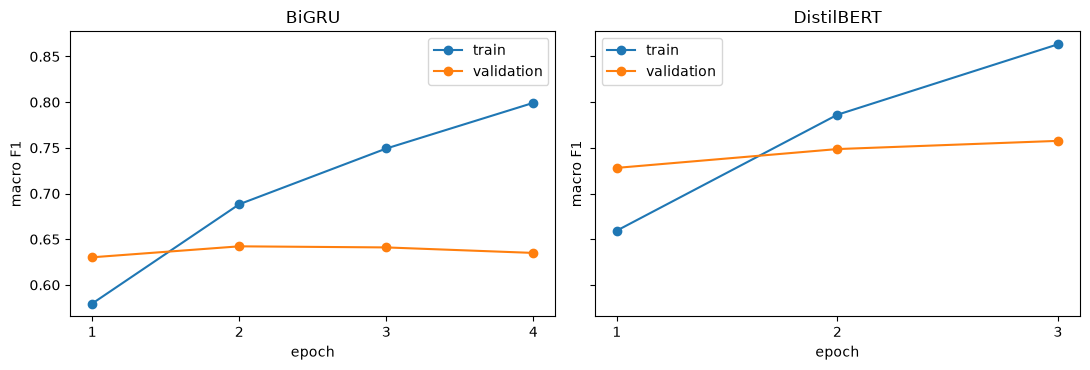

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, (name, hist) in zip(axes, [("BiGRU", gru_hist), ("DistilBERT", bert_hist)]):
    epochs = hist.index + 1
    ax.plot(epochs, hist["macro_f1"], "o-", label="train")
    ax.plot(epochs, hist["val_macro_f1"], "o-", label="validation")
    ax.set(title=name, xlabel="epoch", ylabel="macro F1", xticks=epochs)
    ax.legend()
plt.tight_layout(); plt.savefig(FIG / "nn_history.png", dpi=120); plt.show()

## 5. Įvertinimas
Pagrindinis įvertis yra macro F1, kaip ir SVM užrašų knygelėje. SVM įkeliamas iš `models/svm_6way.joblib`; dažniausios klasės modelis visada atsako „tikras“.

In [9]:
svm = joblib.load(MODELS / "svm_6way.joblib")
preds = {}
for split, df, w, p in [("validation", val, W_val, P_val), ("test", test, W_test, P_test)]:
    preds[split] = {"baseline": np.zeros(len(df), dtype=int),
                    "linear SVM": svm.predict(df["clean_title"]),
                    "BiGRU": gru.predict(w, batch_size=1024, verbose=0).argmax(1),
                    "DistilBERT": bert.predict(p, batch_size=512, verbose=0).argmax(1)}  # klase su didziausia tikimybe
truth = {"validation": y_val, "test": y_test}
pd.DataFrame({(split, name): {"accuracy": accuracy_score(truth[split], p), "macro F1": f1_score(truth[split], p, average="macro")}
              for split in preds for name, p in preds[split].items()}).T.round(4)

accuracy  macro F1
validation baseline      0.3930    0.0940
           linear SVM    0.7623    0.6445
           BiGRU         0.7484    0.6422
           DistilBERT    0.8150    0.7575
test       baseline      0.3963    0.0946
           linear SVM    0.7650    0.6502
           BiGRU         0.7525    0.6507
           DistilBERT    0.8131    0.7547

DistilBERT aiškiai geriausias: testo duomenyse jo macro F1 apie 0,10 didesnis nei SVM, o accuracy apie 5 punktais didesnis, ir validacijos bei testo rezultatai sutampa. Nuo nulio mokytas BiGRU tik prilygsta SVM. Be išankstinio mokymo tinklas mato tas pačias 564 000 antraščių kaip SVM ir iš jų išmoksta maždaug tiek pat; iš anksto išmokytas tinklas jau pradžioje žino, kaip anglų kalbos žodžiai susiję tarpusavyje.

DistilBERT rezultatai pagal klasę testo duomenyse:

In [10]:
print(classification_report(y_test, preds["test"]["DistilBERT"], target_names=CLASSES, digits=4))

                     precision    recall  f1-score   support

               true     0.8712    0.8477    0.8593     23507
      satire/parody     0.7267    0.6998    0.7130      3514
   false connection     0.7116    0.7386    0.7249     11297
   imposter content     0.6694    0.5327    0.5933      1224
manipulated content     0.8402    0.8522    0.8462     17472
 misleading content     0.7411    0.8495    0.7916      2305

           accuracy                         0.8131     59319
          macro avg     0.7600    0.7534    0.7547     59319
       weighted avg     0.8139    0.8131    0.8130     59319



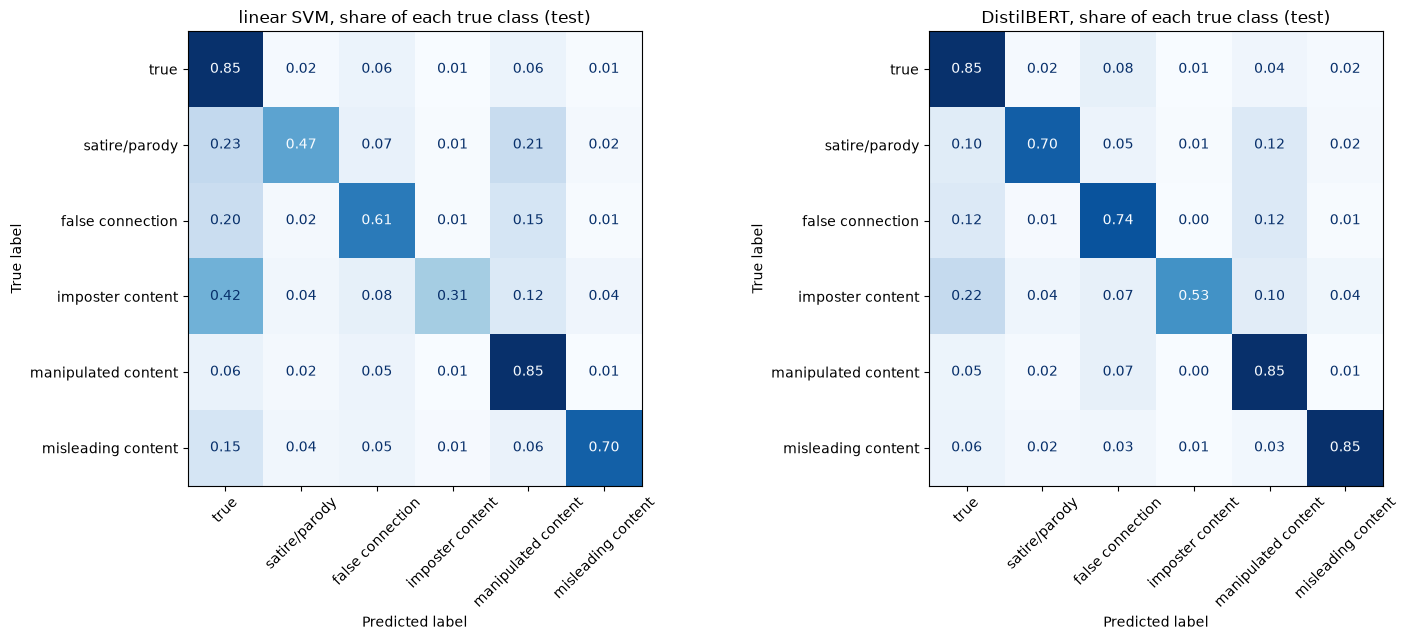

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
for ax, name in zip(axes, ["linear SVM", "DistilBERT"]):
    ConfusionMatrixDisplay.from_predictions(y_test, preds["test"][name], display_labels=CLASSES, normalize="true",  # eilutes procentais, kitaip mazos klases nesimatytu
                                            values_format=".2f", cmap="Blues", colorbar=False, xticks_rotation=45, ax=ax)
    ax.set_title(f"{name}, share of each true class (test)")
plt.tight_layout(); plt.savefig(FIG / "nn_confusion.png", dpi=120); plt.show()

## 6. Kas buvo išbandyta
Pritaikyti įprasti tekstų tinklų mokymo ir gerinimo patarimai, įvertinti validacijos duomenyse (testo duomenys naudoti tik galutinei lentelei aukščiau):

| Tinklas (validacija) | Macro F1 | Accuracy |
|---|---|---|
| BiGRU, nustatymai aukščiau | 0,642 | 74,8 % |
| BiGRU + dropout žodžių vektoriams, max ir average pooling, AdamW su gradientų apribojimu, įšilimas ir kosinuso mokymosi greitis, žymių glotninimas | 0,642 | 75,2 % |
| Tas pats + raidžių šaka (du konvoliuciniai sluoksniai per raides, kaip SVM raidžių sekos), sustabdyta po 4 epochų | 0,640 | 74,5 % |
| BiGRU su DistilBERT žodžių dalimis vietoj žodžių, sustabdyta po 2 epochų, nes reikalinga užpildymo kaukė išjungia greitąją GRU versiją GPU | 0,629 | 74,2 % |
| **Pritaikytas DistilBERT, 3 epochos** | **0,758** | **81,5 %** |

Mokymo gudrybės pakeitė tik tai, kada BiGRU nustojo gerėti, bet ne tai, kiek jis pagerėjo: didžiąją dalį to, ką antraštės gali duoti, jis išmoksta per 2 epochas, o paskui pradeda jas įsiminti (4 skyrius). Pagerėjimą davė išankstinis mokymas. DistilBERT validacijos įvertis dar kilo trečioje epochoje, kai mokymo įvertis jau atitrūko, todėl ketvirta epocha greičiausiai mažai ką pridėtų.